# Feature engineering

Este notebook corresponde a la issue #9. Deriva variables reutilizables a partir de `amenities`, `bathrooms_text` y la antigüedad del anfitrión, dejando el resultado en `src/cleaning.py`.

Las nuevas variables se generan desde `cleaned_df`; no se crean datasets físicos adicionales.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sys.path.insert(0, str(Path("..").resolve()))
from src.cleaning import clean_listings, engineer_features, select_model_features

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.2)
DATA_PATH = Path("../data/raw/listings.csv.gz")
raw_df = pd.read_csv(DATA_PATH, compression="gzip")
cleaned_df = clean_listings(raw_df)
featured_df = engineer_features(cleaned_df)
model_df = select_model_features(featured_df)

print(f"Dataset limpio: {cleaned_df.shape[0]:,} filas x {cleaned_df.shape[1]:,} columnas")
print(f"Dataset con features: {featured_df.shape[0]:,} filas x {featured_df.shape[1]:,} columnas")
print(f"Vista del modelo (MODEL_FEATURES, selección final): {model_df.shape[0]:,} filas x {model_df.shape[1]:,} columnas")

Dataset limpio: 12,610 filas x 93 columnas
Dataset con features: 12,610 filas x 109 columnas
Vista del modelo (MODEL_FEATURES, selección final): 12,610 filas x 23 columnas


## Variables derivadas

- `amenities_count`: número de amenities del anuncio.
- `has_*`: indicadores para amenities con impacto esperado en el precio.
- `bathrooms_count`: número de baños extraído de `bathrooms_text` (`Half-bath` = 0.5).
- `is_shared_bathroom` / `is_private_bathroom`: privacidad del baño.
- `host_tenure_years`: antigüedad del anfitrión a partir de `hosts_time_as_host_years/months`.
- `days_since_last_review`: días desde la última reseña usando el snapshot 17/09/2026.
- `has_reviews`: ya creado en #7 para distinguir anuncios sin historial.

Las columnas originales `amenities` y `bathrooms_text` se eliminan tras la extracción.


In [2]:
engineered_columns = [
    "amenities_count",
    "bathrooms_count",
    "is_shared_bathroom",
    "is_private_bathroom",
    "host_tenure_years",
    "days_since_last_review",
    "days_since_first_review",
    "review_span_days",
]
display(featured_df[engineered_columns].describe().round(2))
print("Columnas raw eliminadas:", "amenities" not in featured_df.columns and "bathrooms_text" not in featured_df.columns)
created = engineered_columns + [column for column in featured_df.columns if column.startswith("has_") and column not in ("has_availability", "has_reviews")]
print("Features creadas aquí que entran en el modelo final:", [column for column in created if column in model_df.columns])
print("Features creadas aquí que NO entran (ver docs/decisiones.md):", [column for column in created if column not in model_df.columns])


,amenities_count,bathrooms_count,is_shared_bathroom,is_private_bathroom,host_tenure_years,days_since_last_review,days_since_first_review,review_span_days
count,12610.00,12602.00,12610.00,12610.00,12606.00,10124.00,10124.00,10124.00
mean,29.36,1.45,0.15,0.09,8.32,140.85,1784.37,1643.52
std,12.54,1.01,0.35,0.28,4.64,382.44,1434.43,1459.03
min,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
25%,21.00,1.00,0.00,0.00,4.33,11.00,588.00,395.00
50%,29.00,1.00,0.00,0.00,8.42,22.00,1412.00,1227.00
75%,37.00,2.00,0.00,0.00,12.83,76.00,2844.00,2724.25
max,86.00,16.00,1.00,1.00,15.67,5566.00,5829.00,5824.00


Columnas raw eliminadas: True
Features creadas aquí que entran en el modelo final: ['bathrooms_count', 'is_shared_bathroom', 'is_private_bathroom', 'has_air_conditioning', 'has_heating', 'has_hair_dryer', 'has_parking', 'has_self_checkin', 'has_dedicated_workspace', 'has_tv', 'has_pool', 'has_elevator', 'has_dishwasher']
Features creadas aquí que NO entran (ver docs/decisiones.md): ['amenities_count', 'host_tenure_years', 'days_since_last_review', 'days_since_first_review', 'review_span_days', 'has_washer', 'has_clothes_dryer']


## Amenities y precio

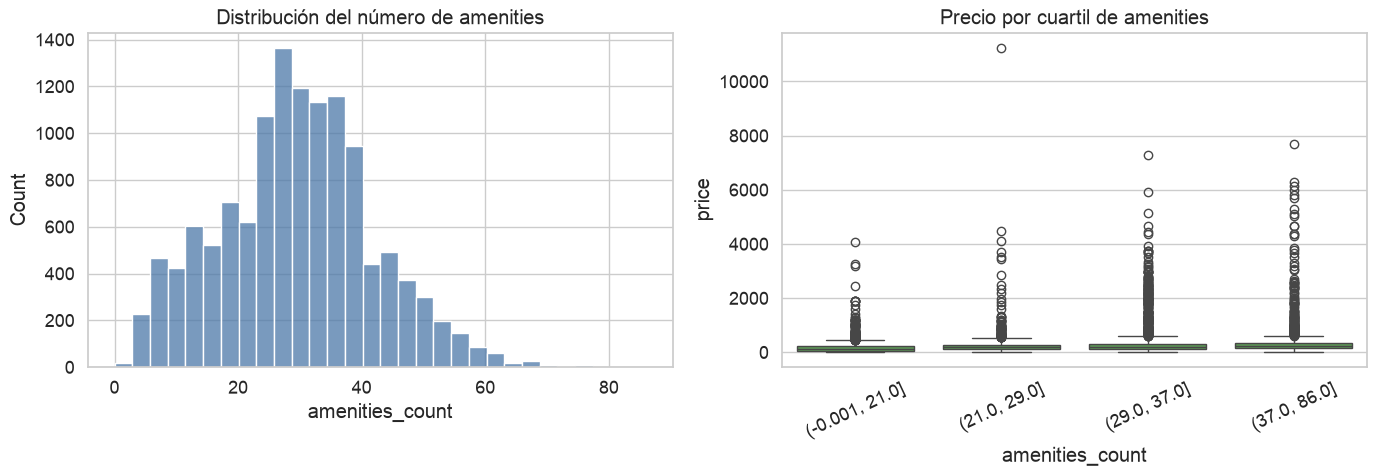

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(featured_df["amenities_count"], bins=30, ax=axes[0], color="#4C78A8")
axes[0].set_title("Distribución del número de amenities")
sns.boxplot(data=featured_df, x=pd.qcut(featured_df["amenities_count"], 4, duplicates="drop"), y="price", ax=axes[1], color="#54A24B")
axes[1].set_title("Precio por cuartil de amenities")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

La mayoría de los anuncios concentra entre 20 y 40 amenities. A mayor número de amenities, la mediana del precio tiende a aumentar, aunque con bastante dispersión, por lo que esta variable es útil pero no suficiente por sí sola.

## Baños y privacidad

In [4]:
display(featured_df.groupby("is_shared_bathroom", dropna=False)["price"].median().round(2))
display(featured_df.groupby("bathrooms_count", dropna=False)["price"].median().round(2).head(10))

is_shared_bathroom
0    213.7
1    57.97
Name: price, dtype: Float64

bathrooms_count
0.0     143.4
0.5     55.04
1.0    174.33
1.5    171.33
2.0    246.58
2.5    260.85
3.0    326.15
3.5     296.8
4.0     574.0
4.5     692.5
Name: price, dtype: Float64

## Antigüedad del anfitrión

En este snapshot `host_since` está vacío, por lo que la antigüedad se calcula con `hosts_time_as_host_years` y `hosts_time_as_host_months`.

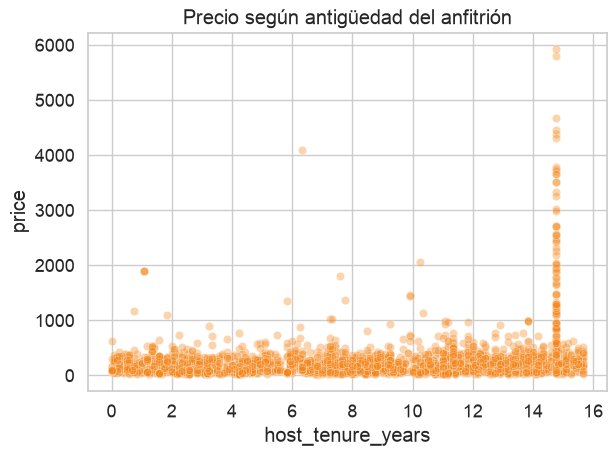

In [5]:
sns.scatterplot(data=featured_df.sample(min(3000, len(featured_df)), random_state=42), x="host_tenure_years", y="price", alpha=0.35, color="#F58518")
plt.title("Precio según antigüedad del anfitrión")
plt.tight_layout()
plt.show()

Los anfitriones con mayor antigüedad muestran una ligera tendencia a precios más altos, pero la relación es débil y muy dispersa. Conviene combinarla con otras variables del alojamiento.

## Decisiones

- `amenities` se resume en un conteo y en indicadores de amenities relevantes; la lista original se elimina para evitar texto libre en el modelo.
- `bathrooms_text` se convierte en número de baños y en indicadores de baño compartido/privado.
- La antigüedad del anfitrión se calcula sin usar el precio ni el target.
- `engineer_features()` es idempotente y se integra en `clean_listings()` para que los siguientes notebooks usen las nuevas variables automáticamente.

> **Nota (selección final):** no todas estas variables entran en el modelo. La selección de 23 variables para anuncios nuevos se hace con train en `02_eda_classes.ipynb` (sección 6) y se documenta en `docs/decisiones.md` («Simplificación de variables: de 71 a 23»). De lo creado aquí entran `bathrooms_count`, `is_shared_bathroom`, `is_private_bathroom` y 10 indicadores `has_*`.